# DailyWildfireCAN: Representative Sample

This notebook explores one raw fire file (`fire_2024_188.h5`) and one training sample from the [DailyWildfireCAN dataset](https://huggingface.co/datasets/DailyWildfireCAN/DailyWildfireCAN). The first cell downloads the representative sample (~200 MB) from Hugging Face.

In [ ]:
import os
from huggingface_hub import snapshot_download

local_dir = snapshot_download(
    repo_id="DailyWildfireCAN/DailyWildfireCAN",
    repo_type="dataset",
    allow_patterns=["representative_sample/data/*"],
    local_dir="hf_sample",
)
# The cells below use paths relative to representative_sample/ (e.g. data/fire_2024_188.h5)
os.chdir(os.path.join(local_dir, "representative_sample"))

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
from tqdm import tqdm
from collections import defaultdict
from pathlib import Path
import glob
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
import math
import json
import time
import h5py
import torch.nn.functional as F
from pyproj import CRS, Transformer
import h5py

# Raw Sample

In [2]:
def print_h5_file_structure(h5_path):
    """
    Opens an H5 file and prints its entire internal hierarchy tree,
    including groups, dataset dimensions, and custom metadata attributes.
    """
    h5_path = Path(h5_path)
    if not h5_path.exists():
        print(f"Error: File not found at '{h5_path}'")
        return

    def _tree_callback(name, obj):
        # Calculate indentation depth based on the H5 path slashes
        indent = "    " * name.count("/")
        base_name = name.split('/')[-1]
        
        if isinstance(obj, h5py.Dataset):
            print(f"{indent}📄 Dataset: {base_name} | Shape: {obj.shape} | Type: {obj.dtype}")
        elif isinstance(obj, h5py.Group):
            print(f"{indent}📁 Group: {base_name}")
            
        # Print any metadata attributes attached directly to this specific object
        if obj.attrs:
            for attr_key, attr_val in obj.attrs.items():
                print(f"{indent}   ↳ 🏷️ Attr: {attr_key} = {attr_val}")

    # Open and inspect the file
    with h5py.File(h5_path, 'r') as f:
        print(f"\n{'='*60}\nSTRUCTURE MAP FOR: {h5_path.name}\n{'='*60}")
        
        # Print root level global attributes
        if f.attrs:
            print("📁 Root Attributes:")
            for k, v in f.attrs.items():
                print(f" ↳ 🏷️ Global Attr: {k} = {v}")
            print("-" * 40)
            
        # Recursively visit and print all internal groups and matrices
        f.visititems(_tree_callback)
        print(f"{'='*60}\nEnd of File Structure Map\n{'='*60}")

In [3]:
h5_output_folder = 'data'

h5_file = f'{h5_output_folder}/fire_2024_188.h5'
tile_id = 'tile_189_127'
day_id = 6

print_h5_file_structure(h5_file)


STRUCTURE MAP FOR: fire_2024_188.h5
📁 Root Attributes:
 ↳ 🏷️ Global Attr: deg_crs = EPSG:4269
 ↳ 🏷️ Global Attr: fire_id = 2024_188
 ↳ 🏷️ Global Attr: meter_crs = EPSG:3347
 ↳ 🏷️ Global Attr: pixel_size = 90
 ↳ 🏷️ Global Attr: year = 2024
----------------------------------------
📁 Group: tile_188_127
   ↳ 🏷️ Attr: tile_col = 188
   ↳ 🏷️ Attr: tile_row = 127
    📁 Group: coords
        📄 Dataset: theoretical_easting | Shape: (256, 256) | Type: int64
        📄 Dataset: theoretical_lat | Shape: (256, 256) | Type: float64
        📄 Dataset: theoretical_lon | Shape: (256, 256) | Type: float64
        📄 Dataset: theoretical_northing | Shape: (256, 256) | Type: int64
    📁 Group: days
        📁 Group: day_006
           ↳ 🏷️ Attr: DOB = 203
           ↳ 🏷️ Attr: end_utc = 2024-07-22T07:00:00
           ↳ 🏷️ Attr: fireday = 6
           ↳ 🏷️ Attr: month = 7
           ↳ 🏷️ Attr: noon_utc = 2024-07-21T19:00:00
           ↳ 🏷️ Attr: start_utc = 2024-07-21T07:00:00
            📁 Group: features


In [5]:
def visualize_h5_tile_static_multi(file_path, tile_id, features, titles, main_title=''):
    """
    Opens the H5 file, navigates to the specific tile, and plots a list of static features.
    """
    num_features = len(features)
    
    # Determine Grid Layout
    if num_features == 1:
        rows, cols = 1, 1
        figsize = (8, 6)
    elif num_features == 3:
        rows, cols = 1, 3
        figsize = (18, 5)
    elif num_features == 4:
        rows, cols = 2, 2
        figsize = (12, 10)
    elif num_features == 6:
        rows, cols = 2, 3
        figsize = (16, 10)
    else:
        # Generic fallback for any other number
        cols = math.ceil(math.sqrt(num_features))
        rows = math.ceil(num_features / cols)
        figsize = (cols * 6, rows * 5)

    # Setup Plot
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    
    # Add a border surrounding the entire figure
    fig.patch.set_edgecolor('black')
    fig.patch.set_linewidth(3)
    
    # Add the main title
    fig.suptitle(main_title, fontsize=20, fontweight='bold', y=0.98)
    
    # Flatten axes
    axes = np.atleast_1d(axes).flatten()

    with h5py.File(file_path, 'r') as f:
        for i, (feature, title) in enumerate(zip(features, titles)):
            ax = axes[i]
            path = f"{tile_id}/static_features/{feature}"
            
            if path not in f:
                ax.set_title(f"Missing: {feature}")
                ax.axis('off')
                continue
                
            # Read the array
            data = f[path][:]
            
            if feature == 'landcover':
                # Original SCANFI categorical data (1-8)
                masked_data = np.ma.masked_where(data == 255, data)
                
                scanfi_colors = [
                    '#8A9A5B', '#90EE90', '#808080', '#D2B48C', 
                    '#32CD32', '#006400', '#228B22', '#4169E1'
                ]
                cmap = mcolors.ListedColormap(scanfi_colors)
                bounds = np.arange(0.5, 9.5, 1) # Strict boundaries for classes 1-8
                norm = mcolors.BoundaryNorm(bounds, cmap.N)
                
                im = ax.imshow(masked_data, cmap=cmap, norm=norm, interpolation='nearest')
                
                scanfi_ticks = list(range(1, 9))
                scanfi_labels = ["Bryoid", "Herbs", "Rock", "Shrub", "Treed Broadleaf", "Treed Conifer", "Treed Mixed", "Water"]
                cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, ticks=scanfi_ticks)
                cbar.ax.set_yticklabels(scanfi_labels)
                
            elif feature in ['ccrs_landcover']:
                # CCRS Canada Land Cover 2020 (Values 1-19 with gaps)
                masked_data = np.ma.masked_where((data == 0) | (data == 255), data)
                
                colors = np.zeros((20, 3))
                colors[1] = [0, 61, 0]; colors[2] = [148, 156, 112]; colors[5] = [20, 140, 61]
                colors[6] = [91, 117, 43]; colors[8] = [179, 138, 51]; colors[10] = [225, 207, 138]
                colors[11] = [156, 117, 84]; colors[12] = [186, 212, 143]; colors[13] = [64, 138, 112]
                colors[14] = [107, 163, 138]; colors[15] = [230, 174, 102]; colors[16] = [168, 171, 174]
                colors[17] = [220, 33, 38]; colors[18] = [76, 112, 163]; colors[19] = [255, 250, 255]
                
                ccrs_cmap = mcolors.ListedColormap(colors / 255.0)
                bounds = np.arange(-0.5, 20.5, 1) # Strict boundaries for 0-19
                norm = mcolors.BoundaryNorm(bounds, ccrs_cmap.N)
                
                im = ax.imshow(masked_data, cmap=ccrs_cmap, norm=norm, interpolation='nearest')
                
                valid_classes = [1, 2, 5, 6, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
                ccrs_labels = [
                    "Temperate needleleaf", "Sub-polar taiga", "Temperate broadleaf", "Mixed forest",
                    "Shrubland", "Grassland", "Shrubland-lichen", "Grassland-lichen", "Barren-lichen",
                    "Wetland", "Cropland", "Barren land", "Urban", "Water", "Snow and ice"
                ]
                cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, ticks=valid_classes)
                cbar.ax.set_yticklabels(ccrs_labels)

            elif feature in ['annual_disturbance_nbac']:
                # 0 is undisturbed/background and 255 is nodata
                masked_data = np.ma.masked_where((data == 0) | (data == 255), data)
                
                # Group 6, 7, and 8 into a single class (6)
                masked_data = np.ma.where(masked_data == 7, 6, masked_data)
                masked_data = np.ma.where(masked_data == 8, 6, masked_data)
                
                # Custom colors for the 6 resulting disturbance classes
                dist_colors = [
                    '#e31a1c',  # 1: Wildfire (Red)
                    '#ff7f00',  # 2: Harvesting (Orange)
                    '#8c564b',  # 3: Other disturbances (Brown)
                    '#1f78b4',  # 4: Water extension (Blue)
                    '#9467bd',  # 5: Defoliation & Harvesting (Purple)
                    '#bcbd22'   # 6: Defoliation - grouped (Olive)
                ]
                cmap = mcolors.ListedColormap(dist_colors)

                bounds = np.arange(0.5, 7.5, 1) 
                norm = mcolors.BoundaryNorm(bounds, cmap.N)
                
                im = ax.imshow(masked_data, cmap=cmap, norm=norm, interpolation='nearest')
                
                dist_ticks = list(range(1, 7))
                dist_labels = [
                    "Wildfire", 
                    "Harvesting", 
                    "Other disturbances", 
                    "Water extension", 
                    "Defol. & Harvesting", 
                    "Defoliation"
                ]
                cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, ticks=dist_ticks)
                cbar.ax.set_yticklabels(dist_labels)

            else:
                # For continuous static features (elevation, slope, aspect, etc.)
                masked_data = np.ma.masked_where(data == 255, data) 
                im = ax.imshow(masked_data, cmap='viridis')
                fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
                
            # Formatting the subplot axes and smaller title
            ax.set_title(title, fontsize=14, pad=10)
            ax.axis('on')
            ax.set_xticks([])
            ax.set_yticks([])
            
            # Set a subtle border for individual subplots
            for spine in ax.spines.values():
                spine.set_edgecolor('#333333')

    # Turn off any unused subplots
    for j in range(num_features, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout(rect=[0, 0, 1, 0.95]) # Adjust to fit the main title properly
    plt.show()

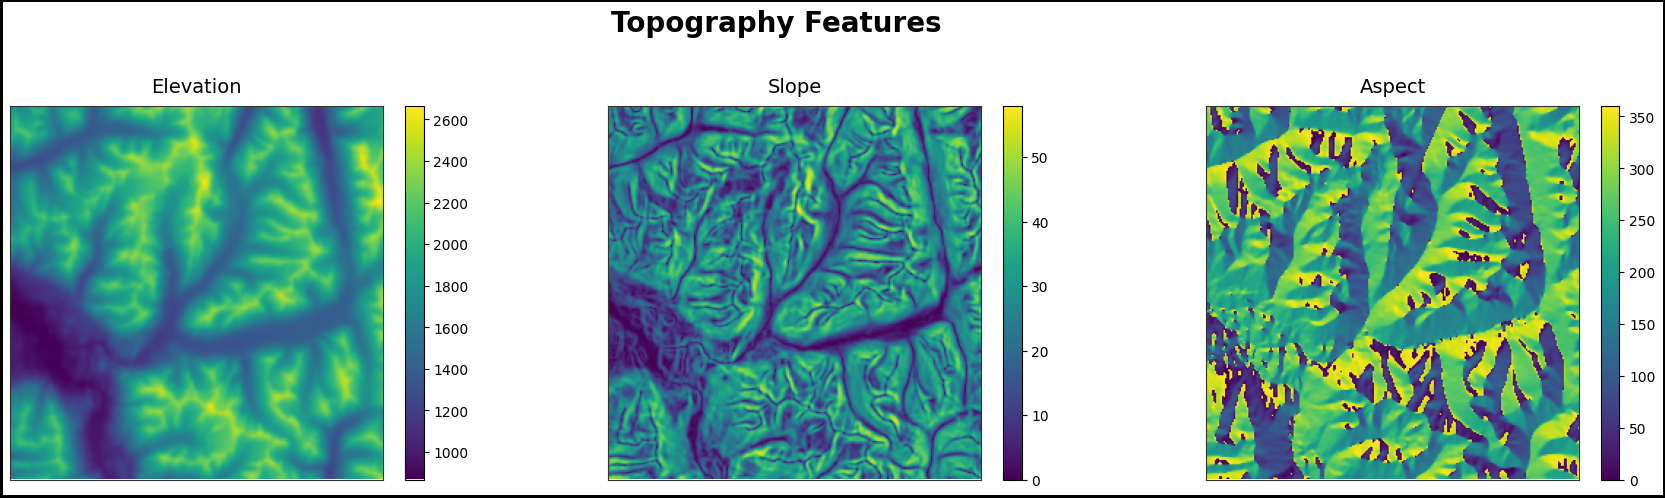

In [6]:
visualize_h5_tile_static_multi(
    file_path=h5_file, 
    tile_id=tile_id, 
    features=['dem', 'slope', 'aspect'], 
    titles=['Elevation', 'Slope', 'Aspect'],
    main_title='Topography Features'
)

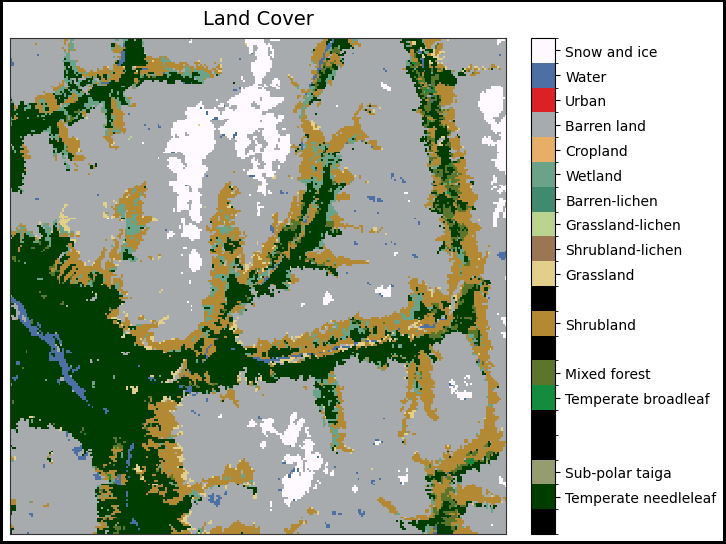

In [7]:
visualize_h5_tile_static_multi(
    file_path=h5_file, 
    tile_id=tile_id, 
    features=['ccrs_landcover'], 
    titles=['Land Cover'],
    main_title=''
)

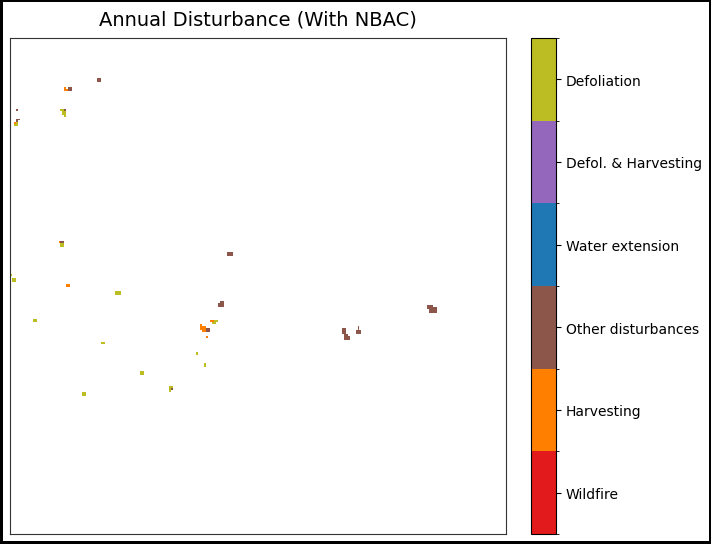

In [8]:
visualize_h5_tile_static_multi(
    file_path=h5_file, 
    tile_id=tile_id, 
    features=['annual_disturbance_nbac'],
    titles=['Annual Disturbance (With NBAC)'],
    main_title=''
)

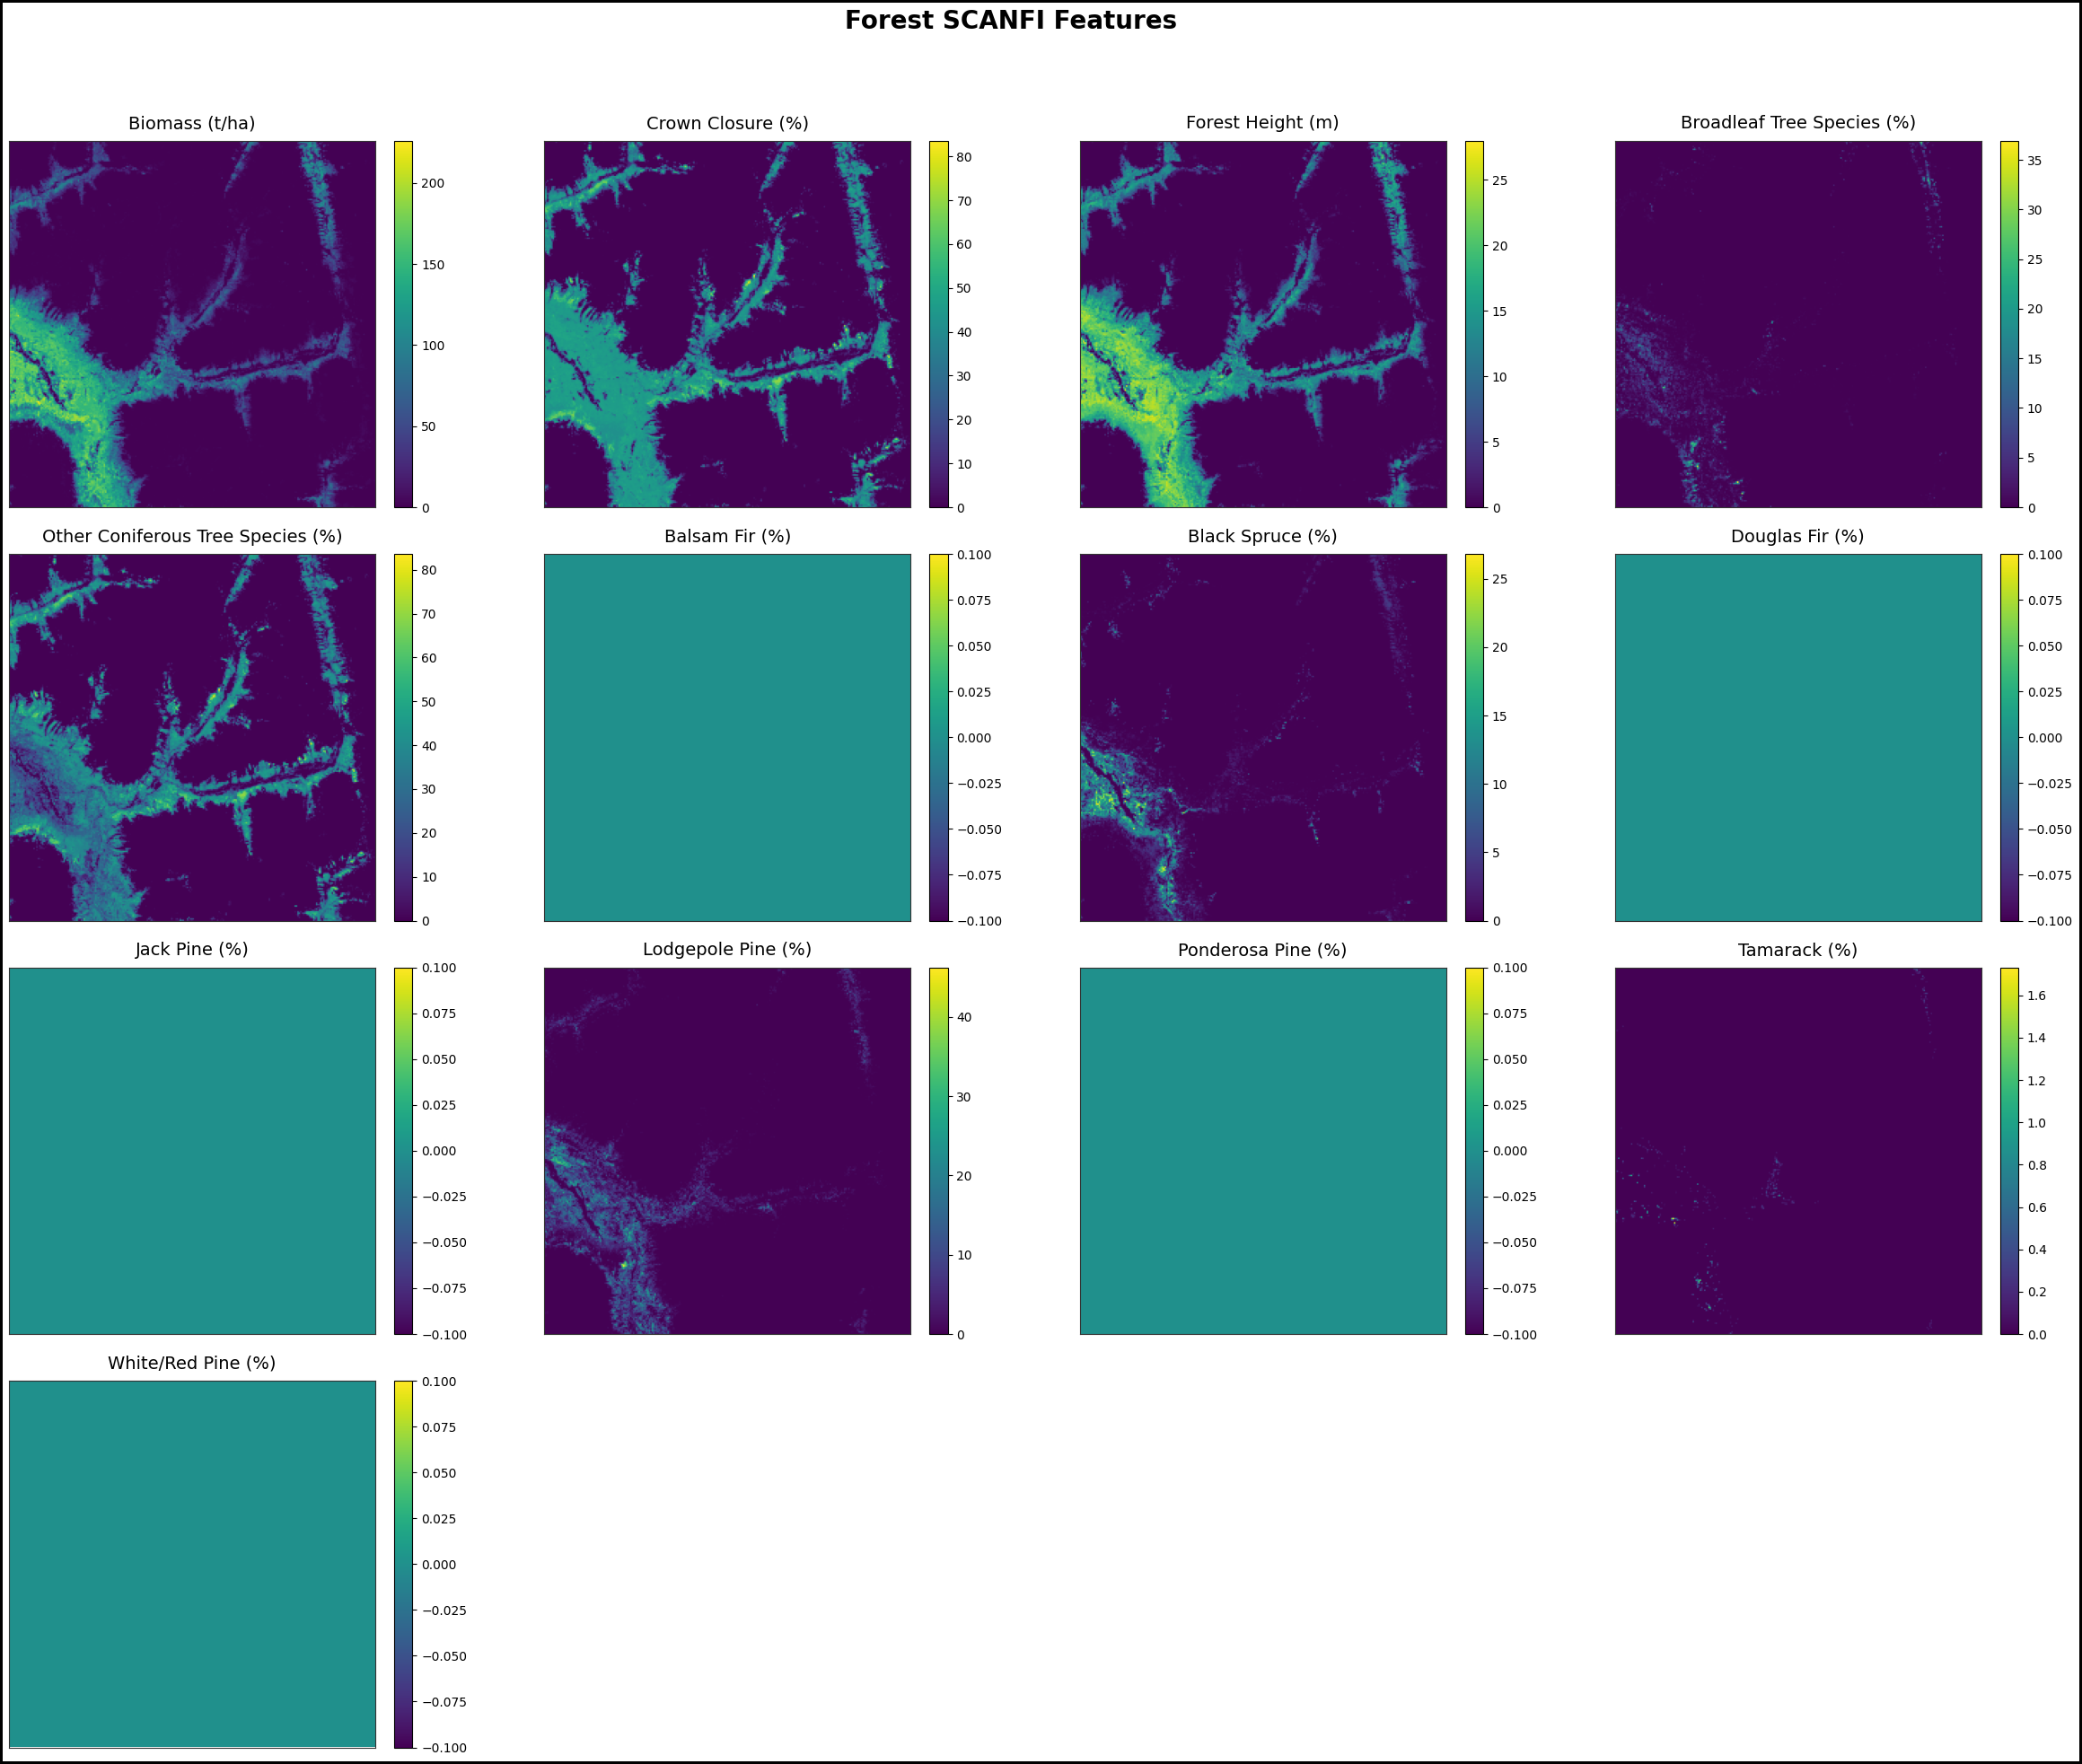

In [12]:
visualize_h5_tile_static_multi(
    file_path=h5_file, 
    tile_id=tile_id, 
    features=['biomass', 
              'closure', 
              'height', 
              'prcb', 
              'prcc', 
              'prc_balsam_fir', 
              'prc_black_spruce', 
              'prc_douglas_fir', 
              'prc_jack_pine',
              'prc_lodgepole_pine', 
              'prc_ponderosa_pine', 
              'prc_tamarack', 
              'prc_white_red_pine'],
    titles = [
        'Biomass (t/ha)',
        'Crown Closure (%)',
        'Forest Height (m)',
        'Broadleaf Tree Species (%)',
        'Other Coniferous Tree Species (%)',
        'Balsam Fir (%)',
        'Black Spruce (%)',
        'Douglas Fir (%)',
        'Jack Pine (%)',
        'Lodgepole Pine (%)',
        'Ponderosa Pine (%)',
        'Tamarack (%)',
        'White/Red Pine (%)'
    ],
    main_title='Forest SCANFI Features'
)



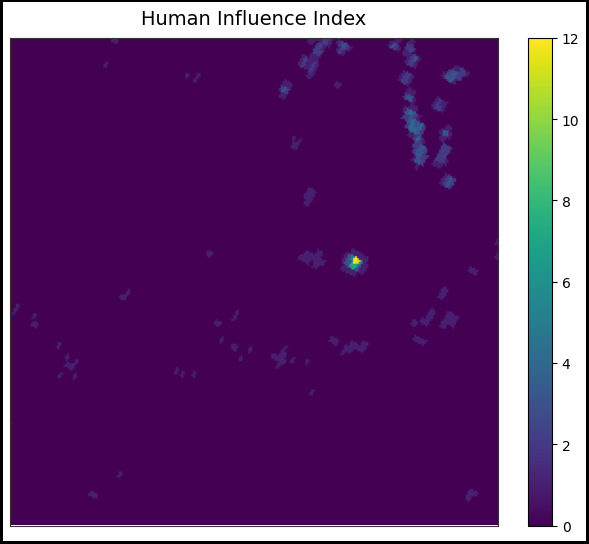

In [13]:
visualize_h5_tile_static_multi(
    file_path=h5_file, 
    tile_id=tile_id, 
    features=['hii'], 
    titles=['Human Influence Index'],
    main_title=''
)

In [14]:
def visualize_h5_tile_day_multi(file_path, tile_id, day, features, titles, main_title='', is_sat=False):
    """
    Opens the H5 file, navigates to the specific tile and day, and plots a list of features.
    """
    num_features = len(features)
    
    # Determine Grid Layout
    if num_features == 1:
        rows, cols = 1, 1
        figsize = (8, 6)
    elif num_features == 3:
        rows, cols = 1, 3
        figsize = (18, 5)
    elif num_features == 4:
        rows, cols = 2, 2
        figsize = (12, 10)
    elif num_features == 6:
        rows, cols = 2, 3
        figsize = (16, 10)
    else:
        # Generic fallback
        cols = math.ceil(math.sqrt(num_features))
        rows = math.ceil(num_features / cols)
        figsize = (cols * 6, rows * 5)

    # Setup Plot
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    
    # Add a border surrounding the entire figure
    fig.patch.set_edgecolor('black')
    fig.patch.set_linewidth(3)
    
    # Add the main title
    fig.suptitle(main_title, fontsize=20, fontweight='bold', y=0.98)
    
    # Flatten axes
    axes = np.atleast_1d(axes).flatten()

    with h5py.File(file_path, 'r') as f:
        day_str = f"day_{int(day):03d}"
        
        for i, (feature, title) in enumerate(zip(features, titles)):
            ax = axes[i]
            
            # Handle is_sat whether it's passed as a single bool or a list of bools
            current_is_sat = is_sat[i] if isinstance(is_sat, list) else is_sat
            
            if not current_is_sat:
                path = f"{tile_id}/days/{day_str}/features/{feature}"
            else:
                path = f"{tile_id}/days/{day_str}/satellite/{feature}"
            
            if path not in f:
                ax.set_title(f"Missing: {feature}")
                ax.axis('off')
                continue
            
            # Read the array into memory
            data = f[path][:]
            
            # Check if the data is binary (our bool masks) or continuous (like weather)
            is_binary = data.dtype == bool or set(np.unique(data)).issubset({0, 1})
            
            if is_binary:
                # For fire masks, lock to 0-1 and use Magma
                im = ax.imshow(data.astype(float), cmap='magma', vmin=0, vmax=1)
            else:
                # For continuous features, let Matplotlib auto-scale
                im = ax.imshow(data, cmap='viridis')
            
            # Add Colorbar
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            
            # Formatting the subplot axes and smaller title
            ax.set_title(title, fontsize=14, pad=10)
            ax.axis('on')
            ax.set_xticks([])
            ax.set_yticks([])
            
            # Set a subtle border for individual subplots
            for spine in ax.spines.values():
                spine.set_edgecolor('#333333')

    # Turn off any unused subplots
    for j in range(num_features, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout(rect=[0, 0, 1, 0.95]) # Adjust to fit the main title properly
    plt.show()

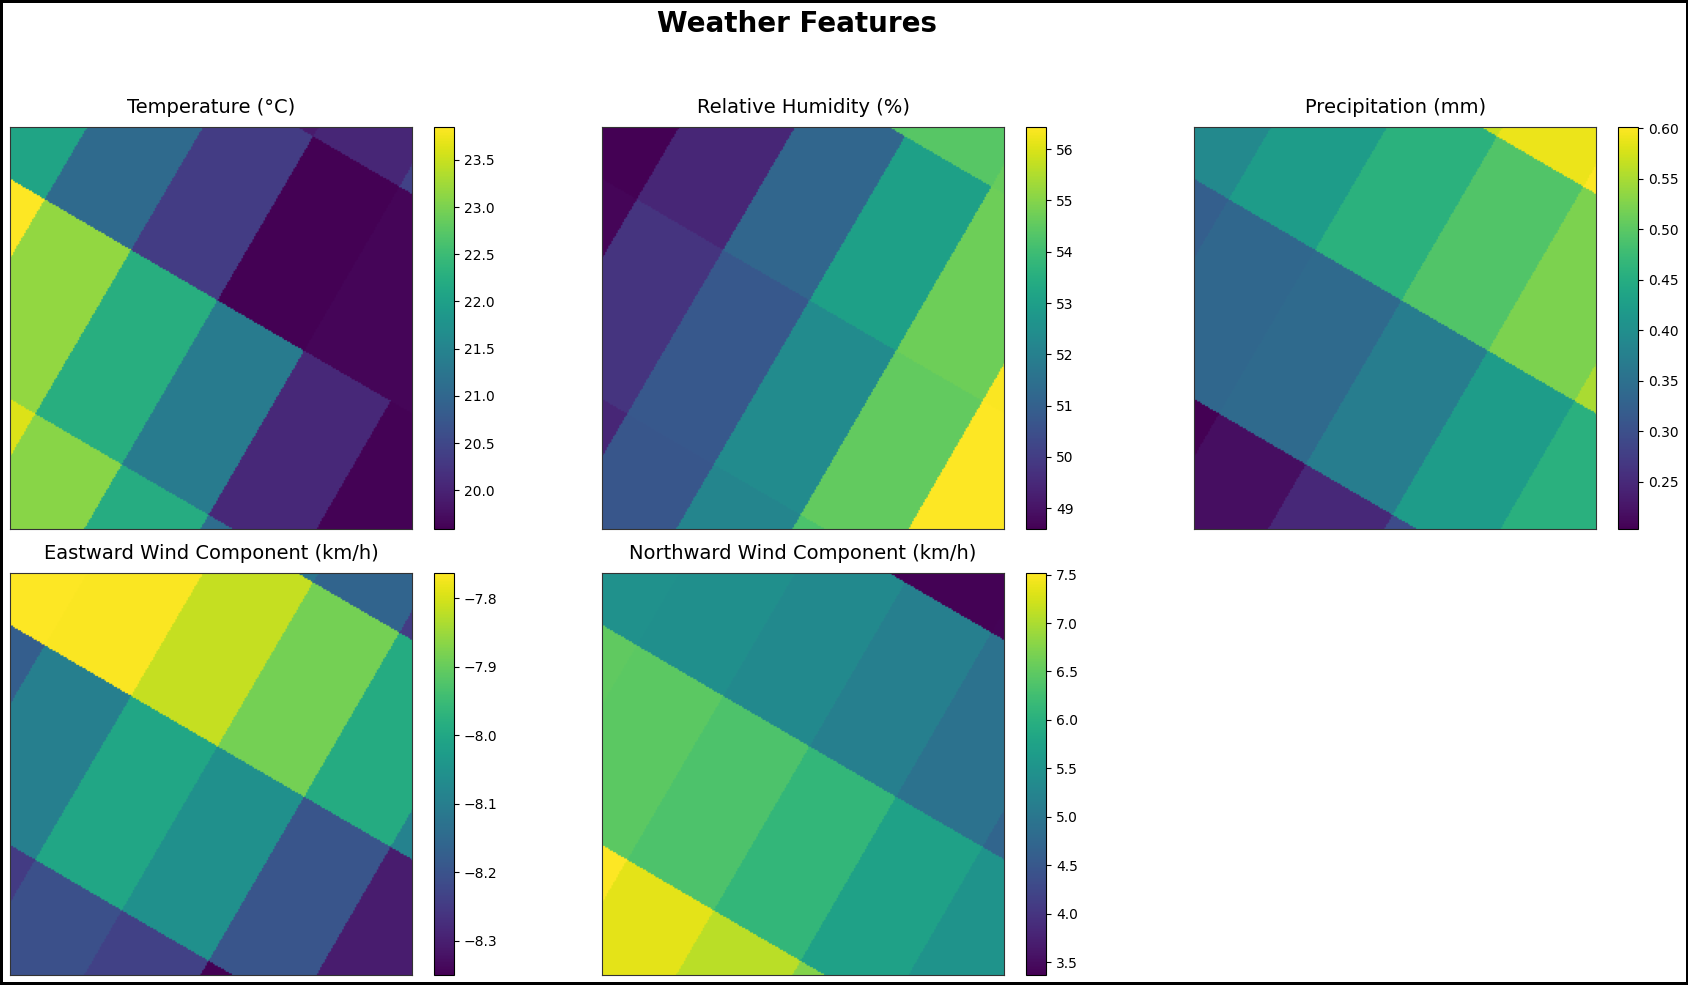

In [15]:
# Weather Features (3 items)
visualize_h5_tile_day_multi(
    file_path=h5_file, 
    tile_id=tile_id,
    day=day_id,
    features=['tmax', 'rh', 'prec', 'u10', 'v10'], 
    titles=['Temperature (°C)', 'Relative Humidity (%)', 'Precipitation (mm)', 'Eastward Wind Component (km/h)', 'Northward Wind Component (km/h)'],
    main_title='Weather Features',
    is_sat=False
)

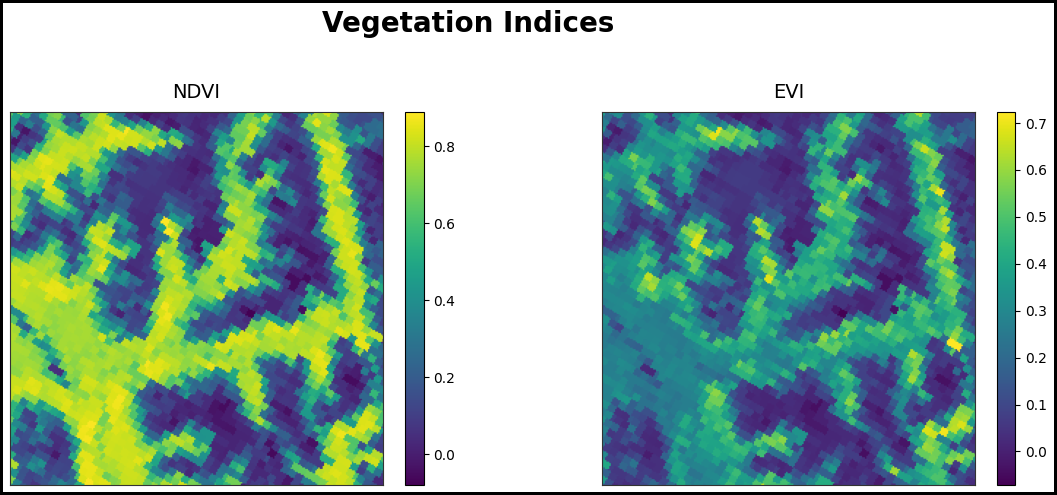

In [16]:
visualize_h5_tile_day_multi(
    file_path=h5_file, 
    tile_id=tile_id,
    day=day_id,
    features=['ndvi', 'evi'], 
    titles=['NDVI', 'EVI'],
    main_title='Vegetation Indices',
    is_sat=False
)

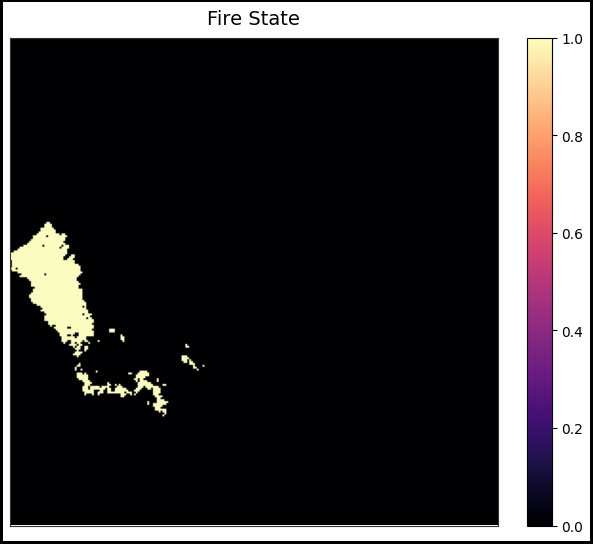

In [17]:
visualize_h5_tile_day_multi(
    file_path=h5_file, 
    tile_id=tile_id, 
    features=['cumuarea'], 
    titles=['Fire State'],
    day=day_id,
    main_title=''
)

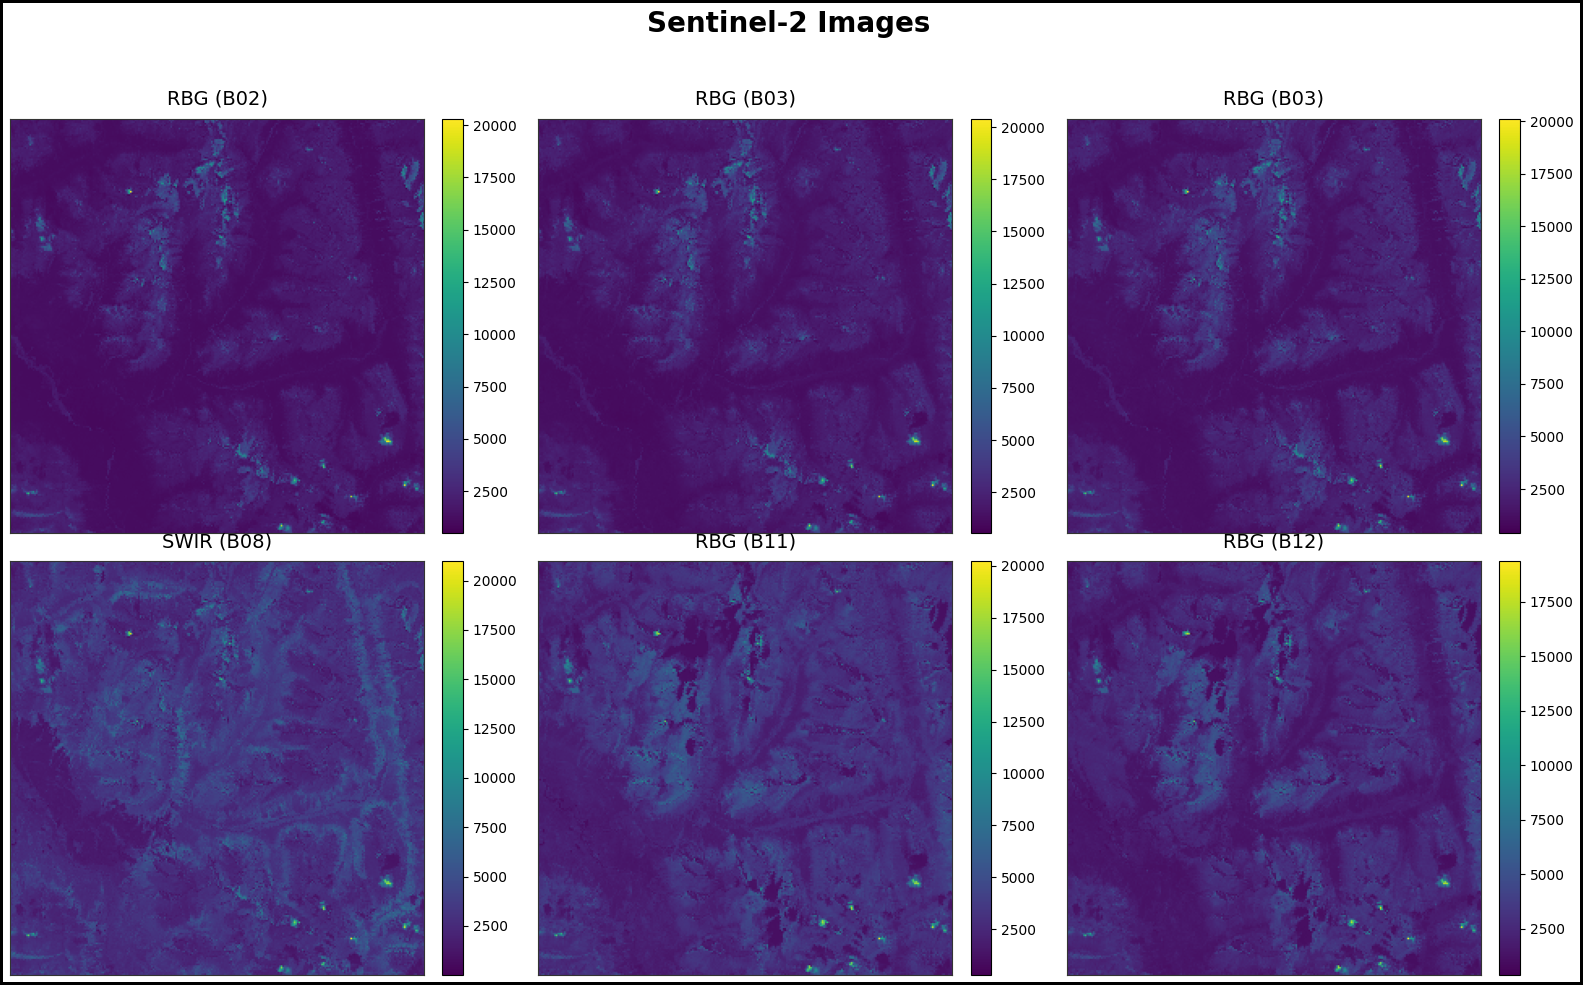

In [18]:
visualize_h5_tile_day_multi(
    file_path=h5_file, 
    tile_id=tile_id,
    day=22,
    # day=day_id,
    features=['s2_b02', 's2_b03', 's2_b04', 's2_b08', 's2_b11', 's2_b12'], 
    titles=['RBG (B02)', 'RBG (B03)', 'RBG (B03)', 'SWIR (B08)', 'RBG (B11)', 'RBG (B12)'], 
    main_title='Sentinel-2 Images',
    is_sat=True
)

# Training Sample

In [21]:
def visualize_numpy_sample(sample, input_names):
    """
    Loads a saved .npz sample and plots all X channels and the Y target in a grid.
    """
    x = sample['x']
    y = sample['y']
    delta_t = sample['delta_t']
    
    # Validation check
    if len(input_names) != x.shape[0]:
        print(f"Warning: You provided {len(input_names)} names, but X has {x.shape[0]} channels")
    
    # Setup the grid
    num_plots = x.shape[0] + 1 
    cols = 5
    rows = int(np.ceil(num_plots / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(20, 4.2 * rows))
    axes = axes.flatten()
    
    # Plot all X (Input) Channels
    for i in range(x.shape[0]):
        ax = axes[i]
        data = x[i]
        
        # Get the feature name, fallback to index if missing
        feat_name = input_names[i] if i < len(input_names) else f"Channel {i}"

        cmap = 'viridis'
        if feat_name == 'dem': cmap = 'terrain'
        elif feat_name == 'prec': cmap = 'Blues'
        elif feat_name == 'tmax': cmap = 'coolwarm'
        elif feat_name in ['ndvi', 'evi', 'closure', 'biomass', 'prcc', 'prcb']: cmap = 'YlGn'
        elif feat_name.startswith('s2_'): cmap = 'RdYlGn_r'
        elif 'mask' in feat_name: cmap = 'magma'
        elif 'mask' in feat_name: cmap = 'RdYlGn_r'
        
        im = ax.imshow(data, cmap=cmap)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        display_name = feat_name
        if 'mask' in feat_name.lower():
            display_name += "\n(up to day T)"

        ax.set_title(f"INPUT:\n{display_name}", fontsize=10, fontweight='bold')
        
        ax.axis('off')

    # Plot the Y (Target) Channel at the end
    ax_y = axes[x.shape[0]]
    im_y = ax_y.imshow(y, cmap='magma') # Red hot for new fire growth
    fig.colorbar(im_y, ax=ax_y, fraction=0.046, pad=0.04)
    
    # Highlight the target title in red
    ax_y.set_title(f"TARGET:\nFire Growth T+1", fontsize=12, fontweight='bold', color='red')
    ax_y.axis('off')
    
    # Hide empty subplots
    for j in range(x.shape[0] + 1, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()

Sample --> X shape: (50, 256, 256)
Sample --> y shape: (256, 256)
Sample --> Fire Date: [2024    7   21]


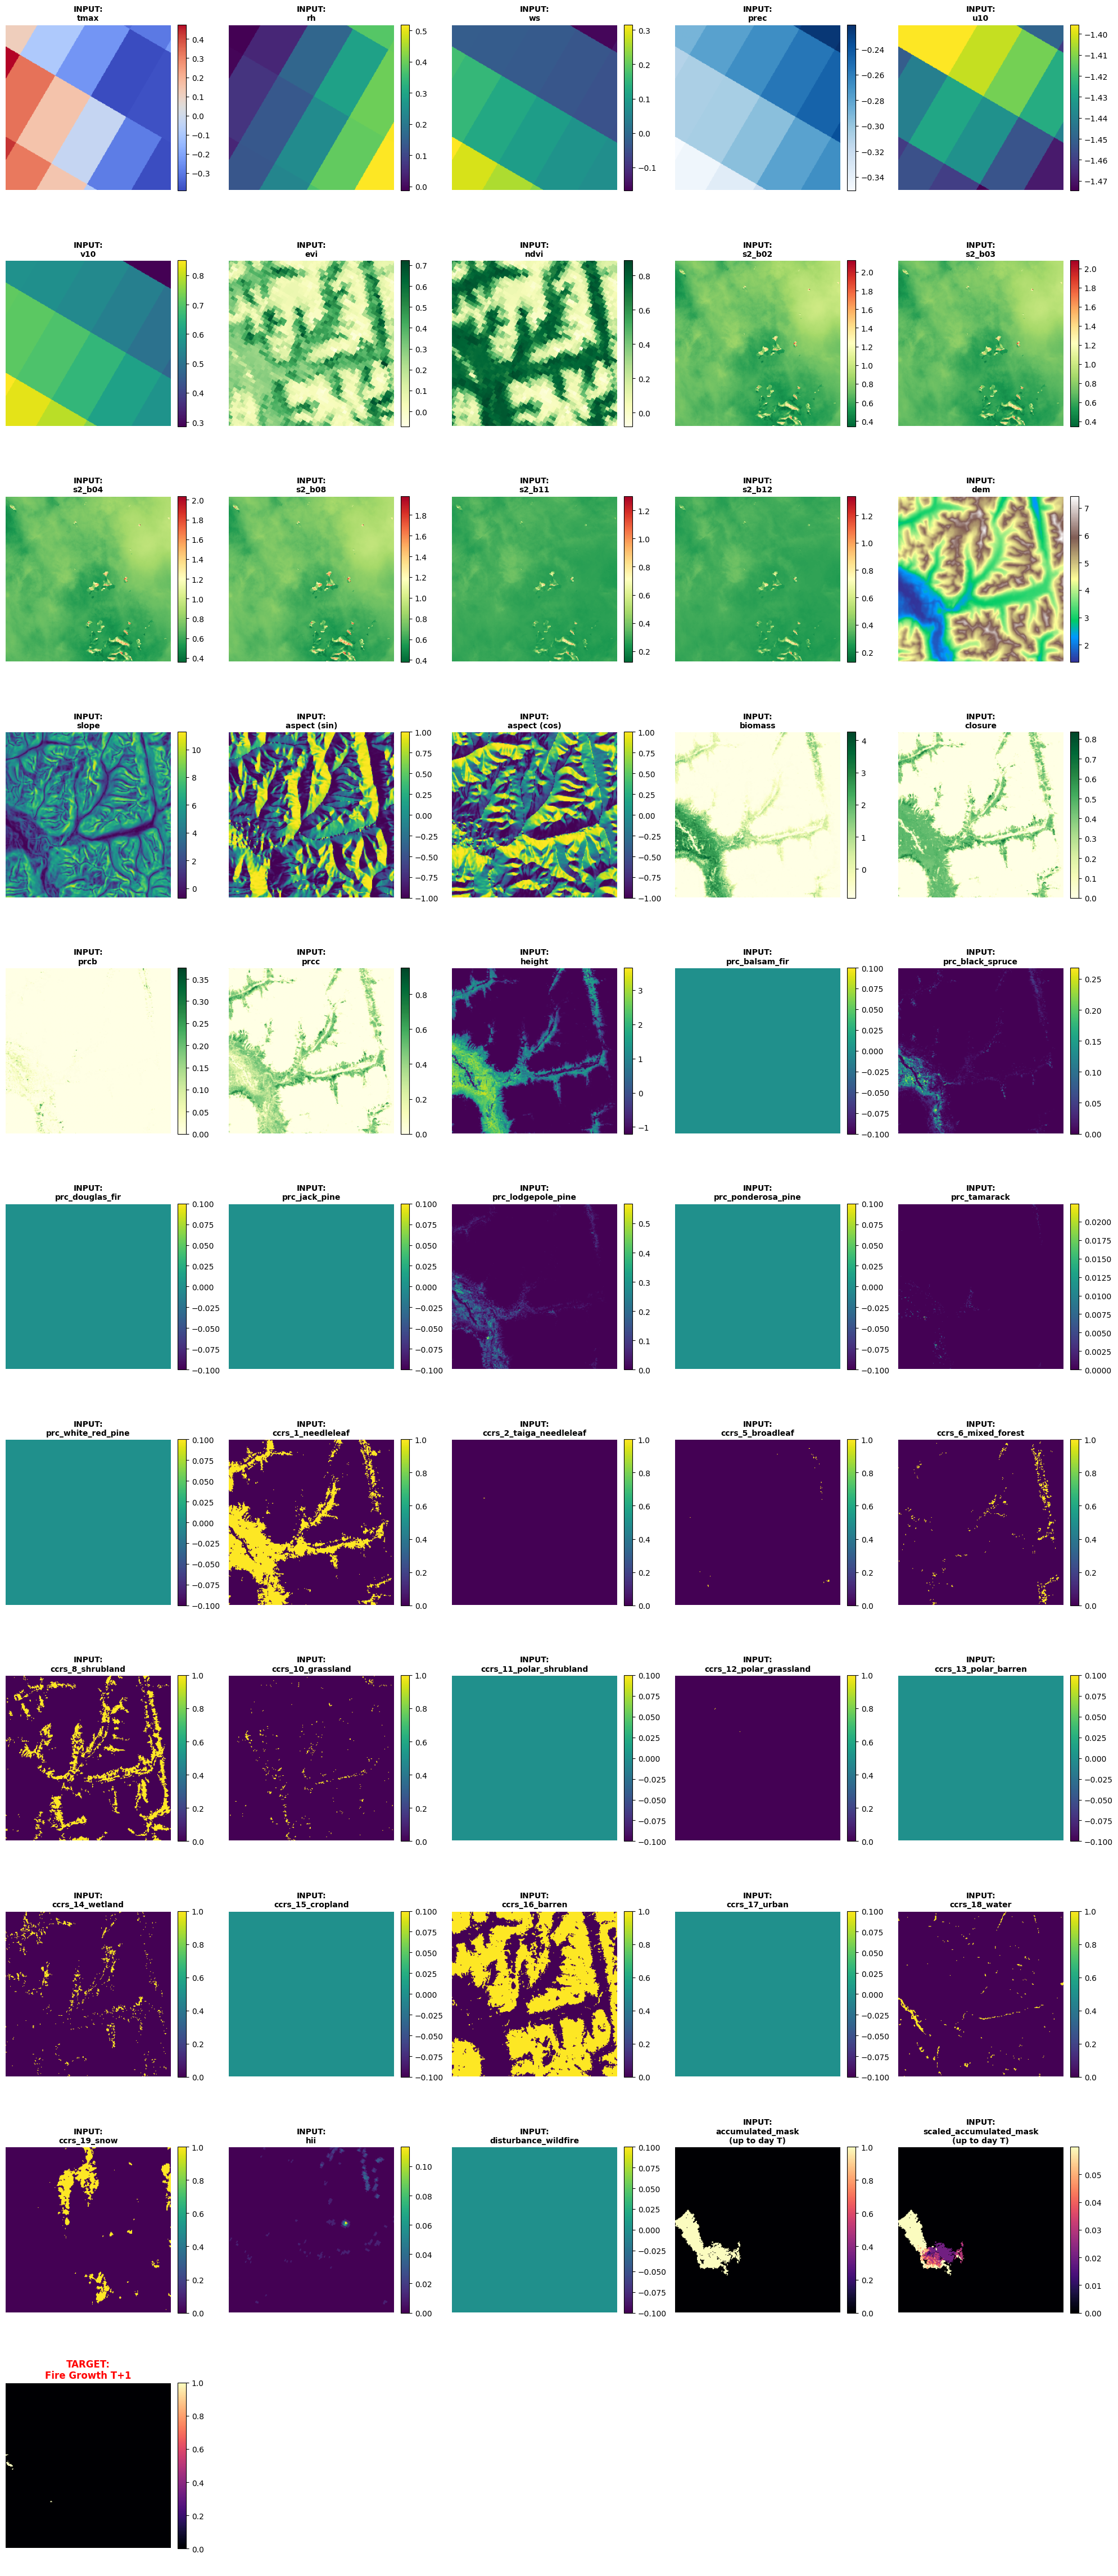

In [24]:
sample_folder = 'data/training_samples'

sample_path = f'{sample_folder}/sample_1521.npz'

with np.load(sample_path) as data:
    # Extract the fields
    x = data['x']
    y = data['y']
    delta_t = data['delta_t']
    fire_date = data['fire_date']
    
    # Build the sample dictionary
    sample = {
        'x': x, 
        'y': y, 
        'delta_t': delta_t, 
        'fire_date': fire_date,
    }
        
print(f"Sample --> X shape: {x.shape}")
print(f"Sample --> y shape: {y.shape}")
print(f"Sample --> Fire Date: {fire_date}")

fire_feat = 'cumuarea'

# 50-channel input names list
input_names = [
    # --- DYNAMIC FEATURES (14) ---
    'tmax', 'rh', 'ws', 'prec', 'u10', 'v10', 'evi', 'ndvi', 
    's2_b02', 's2_b03', 's2_b04', 's2_b08', 's2_b11', 's2_b12',
    
    # --- STATIC FEATURES (TOPOGRAPHY) (4) ---
    'dem', 'slope', 'aspect (sin)', 'aspect (cos)', 
    
    # --- STATIC FEATURES (SCANFI) (13) ---
    'biomass', 'closure', 'prcb', 'prcc', 'height',
    'prc_balsam_fir', 'prc_black_spruce', 'prc_douglas_fir', 'prc_jack_pine',
    'prc_lodgepole_pine', 'prc_ponderosa_pine', 'prc_tamarack', 'prc_white_red_pine',
    
    # --- STATIC FEATURES (CCRS LANDCOVER) (15) ---
    'ccrs_1_needleleaf', 
    'ccrs_2_taiga_needleleaf', 
    'ccrs_5_broadleaf', 
    'ccrs_6_mixed_forest', 
    'ccrs_8_shrubland', 
    'ccrs_10_grassland', 
    'ccrs_11_polar_shrubland', 
    'ccrs_12_polar_grassland', 
    'ccrs_13_polar_barren', 
    'ccrs_14_wetland', 
    'ccrs_15_cropland', 
    'ccrs_16_barren', 
    'ccrs_17_urban', 
    'ccrs_18_water', 
    'ccrs_19_snow',

    # --- STATIC FEATURES (HUMAN INFLUENCE INDEX) (1) ---
    'hii',

    # --- STATIC FEATURES (ANNUAL DISTURBANCE) (1) ---
    'disturbance_wildfire',
    
    # --- FIRE MASKS (2) ---
    'accumulated_mask', 'scaled_accumulated_mask'
]

visualize_numpy_sample(sample, input_names)